In [1]:
from dataclasses import dataclass
from fractions import Fraction
from functools import reduce
from math import lcm

import numpy as np
import matplotlib.pyplot as plt
import time

import spcm
from spcm import units


plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": False})

from pathlib import Path
import json
import sys
from Equipments.ThorCamLinux import Camera, LiveMonitor, diagnostics, list_cameras, output_path, save_frame
from DataProcessing.TweezerAnalyze import analyze_1D_tweezer_array

# Override the unavailable Times New Roman default set by DataProcessing imports.
plt.rcParams['font.family'] = 'DejaVu Serif'


In [103]:
@dataclass(frozen=True)
class AWGConfig:
    card_resource: str = "/dev/spcm0"
    sample_rate_mhz: int = 625
    segment_alignment_samples: int = 32
    sequence_memory_slots: int = 4
    max_loop_samples: int = 10_000_000

    empty_tone_ramp_us: float = 2.0
    movement_us_per_site: float = 5.0
    minimum_movement_us: float = 2.0
    phase_settle_us: float = 10.0
    phi1_rad: float = 0.0

    dac_headroom: float = 0.85
    dac_max_code: int = 32767
    min_output_range_mv: float = 80.0
    max_output_range_mv: float = 2500.0


@dataclass(frozen=True)
class AWGChannelConfig:
    index: int
    single_tone_amplitude_mv: float
    load_ohm: int
    max_average_output_power_dbm: float = -2


class signal_generator:
    # 1. Shared functions
    def __init__(self, config, channel_configs):
        self.config = config
        self.channel_configs = tuple(sorted(channel_configs, key=lambda ch: ch.index))
        self.length = len(self.channel_configs) # the number of the active channels

    def get_calibrated_relative_amplitude(self, frequency):
        return outter_function(frequency)

    # def get_calibrated_relative_amplitude(self, frequency):
        
    #     return 
    
    def generate_waveform(self,frequencies_mhz, phase0):
        """
        generate the waveform for both static stage and dynamic stage
    
        the frequencies_mhz should be a 2D array, the first index is the tone and the second index is the sample. frequency is a function of time when it is dynamic
    
        relative amplitudes calibrated
    
        phase0 is a 1d array that contains the initial phase of the waveform
    
        sample_rate_mhz is the card sample rate
        """
        
        if len(frequencies_mhz) !=len(phase0):
            raise ValueError("The number of phase should match the number of the tones")
            
        increments = 2*np.pi*frequencies_mhz/self.config.sample_rate_mhz
        phase = phase0[:, None] + np.cumsum(np.column_stack([np.zeros(len(phase0)), increments[:, :-1]]), axis=1)
        relative_amplitudes = self.get_calibrated_relative_amplitude(frequencies_mhz)
        waveform = np.sum(relative_amplitudes * np.cos(phase), axis=0)
        phase_next = phase0 + np.sum(increments, axis=1)
        return waveform, phase, phase_next

    def get_output_range_mv(self,waveform, single_tone_amplitude_mv ):
        """
        calculate the channel output range in mV based on the waveform and single tone amplitude

        no worry about the relative amp, because it is counted in the waeform
        """
        
        worst_case_peak_mv = np.max(np.abs(waveform)) * single_tone_amplitude_mv
        output_range_mv = np.ceil(worst_case_peak_mv/self.config.dac_headroom)
        if output_range_mv < self.config.min_output_range_mv:
            raise ValueError("Requested per-tone amplitude is too low")
        if output_range_mv > self.config.max_output_range_mv:
            raise ValueError("Requested per-tone amplitude exceeds the available channel range")
        return output_range_mv

    def convert_waveform_to_dac_samples(self, waveform, single_tone_amplitude_mv, output_range_mv):
        """
        convert the wavefom to 16bit DAC samples. For the entire sequence, the output_range should keep fixed
        """
        
        normalized = np.asarray(waveform)*single_tone_amplitude_mv/output_range_mv
        return np.rint(normalized*self.config.dac_max_code).astype(np.int16)

    # 2. Static signal generation
    def as_exact_mhz(self, value):
        if isinstance(value, Fraction):
            return value
        if isinstance(value, (int, np.integer)):
            return Fraction(int(value))
        if isinstance(value, (float, np.floating)):
            return Fraction(str(float(value)))
        return Fraction(value)

    def equally_spaced_frequencies_mhz(self, start_mhz, stop_mhz, count):
        start = self.as_exact_mhz(start_mhz)
        stop = self.as_exact_mhz(stop_mhz)
        spacing = (stop-start)/(count-1)
        return np.array([start+i*spacing for i in range(count)], dtype=object)

    def generate_exact_frequencies_mhz(self, frequencies: list):
        return np.array([self.as_exact_mhz(f) for f in frequencies], dtype=object)

    def common_phase_period_samples(self, frequencies_mhz, sample_rate_mhz):
        """Return the smallest N for which N*f/fs is integral for every tone."""
        fs = Fraction(sample_rate_mhz)
        denominators = [(self.as_exact_mhz(f)/fs).denominator for f in frequencies_mhz]
        return lcm(*denominators, 1)

    def generate_static_waveform_one_channel(self, frequencies_mhz, start_phases, loop_samples):
        frequency = np.asarray(frequencies_mhz, dtype=float)
        phase0 = np.asarray(start_phases, dtype=float)
    
        frequency_matrix = np.repeat(frequency[:, None], loop_samples, axis=1)
        waveform, phase, phase_next = self.generate_waveform(frequency_matrix, phase0)
        return waveform, phase_next


    def generate_static_signal(self, frequencies_mhz_dict, phases_dict, output_ranges_mv_dict = None):
        if frequencies_mhz_dict.keys() != phases_dict.keys():
            raise ValueError("The frequency, phases channel indices do not match")

        channel_rows_dict = {channel.index: index for index, channel in enumerate(self.channel_configs)} # the dict is like this {0:0,2:1,}, this dict stores the configured channels
        if not frequencies_mhz_dict.keys() <= channel_rows_dict.keys():
            raise ValueError("The frequencies exceed the configured channels")

        initial_sequence = False
        if output_ranges_mv_dict == None:
            initial_sequence = True

        base_periods = []

        # the following code loops all active channels and find the lcm for each channel, then stored in the base_periods
        for active_channel in frequencies_mhz_dict.keys():
            channel_frequencies = frequencies_mhz_dict[active_channel]
            channel_phases = phases_dict[active_channel]
            if channel_frequencies.ndim != 1 or channel_phases.ndim != 1:
                raise ValueError("Each channel must contain one-dimensional tone arrays")
            if len(channel_frequencies) != len(channel_phases):
                raise ValueError(f"CH{active_channel} frequency, phases counts do not match")
            exact_frequencies = np.array([self.as_exact_mhz(f) for f in channel_frequencies])
            base_period = self.common_phase_period_samples(exact_frequencies, self.config.sample_rate_mhz)
            base_periods.append(base_period)
            
        # find the common lcm for all active channels
        loop_samples = lcm(*base_periods, self.config.segment_alignment_samples)
        if loop_samples > self.config.max_loop_samples:
            raise ValueError("Static hold period exceeds max_loop_samples")

        #this should be a rectangular since the segments for all channels should align. The first index also cover all configured channels
        samples_matrix = np.zeros((self.length, loop_samples), dtype=np.int16) # shape: number of configured channels * sample length
        if initial_sequence:
            output_ranges_mv_dict = {configured_channel.index: self.config.min_output_range_mv for configured_channel in self.channel_configs} # shape: number of configured channels
        phases_next_dict = {active_channel: np.zeros(0) for active_channel in frequencies_mhz_dict.keys()} # shape: number of configured channels, for each key, the value is an array with the size of number of tones

        # the following code loop the active channels and update the samples and output ranges
        for active_channel in frequencies_mhz_dict.keys():
            waveform, phase_next = self.generate_static_waveform_one_channel(frequencies_mhz_dict[active_channel], phases_dict[active_channel], loop_samples)
            phases_next_dict[active_channel] = phase_next

            single_tone_amplitude_mv = self.channel_configs[channel_rows_dict[active_channel]].single_tone_amplitude_mv
            
            if initial_sequence:
                output_range_mv = self.get_output_range_mv(waveform, single_tone_amplitude_mv)
            else:
                output_range_mv = output_ranges_mv_dict[active_channel]
                
            samples = self.convert_waveform_to_dac_samples(waveform, single_tone_amplitude_mv, output_range_mv)
            output_ranges_mv_dict[active_channel] = output_range_mv
            samples_matrix[channel_rows_dict[active_channel]] = samples

        return samples_matrix, output_ranges_mv_dict, frequencies_mhz_dict, phases_next_dict

        
    # 2.1 initial equal spacing static signal generation
    def generate_initial_phases(self, frequencies, phi1=0.0):
        amplitudes = self.get_calibrated_relative_amplitude(frequencies)
        powers = amplitudes**2/np.sum(amplitudes**2)
        phases = np.zeros(len(amplitudes))
        phases[0] = phi1
        for m in range(1, len(amplitudes)):
            phases[m] = phi1 + 2*np.pi*sum((m-i)*powers[i] for i in range(m))
        return np.mod(phases, 2*np.pi)

    # 3. dynamic signal generation
    def find_target_position(self, initial_occupancy):
        position = np.flatnonzero(initial_occupancy)
        n = len(initial_occupancy)
        m = len(position)
        candidates = [np.arange(m) + i for i in range(n - m + 1)]
        distances = [np.sum(np.abs(position - c)) for c in candidates]
        return {"start": position, "target": candidates[np.argmin(distances)]}
    
    def transfer_function(self, s):
        return 10*s**3 - 15*s**4 + 6*s**5

    
    def generate_dynamic_waveform_one_channel(self, start_frequencies_mhz, start_phases, occupancy_list: list, target_occupancy_list: list, n_samples: float):

        # print(start_frequencies_mhz)
        if len(start_frequencies_mhz) != len(start_phases):
            raise ValueError("the lens of the start frequencies doesn't match the start phases")
        if len(occupancy_list) != len(target_occupancy_list):
            raise ValueError("the occupancy lists do not match")

            
        s = np.linspace(0.0, 1.0, n_samples)
        h = self.transfer_function(s)
        start_frequencies_occupancy = np.asarray(start_frequencies_mhz[occupancy_list], dtype=float)
        start_phases_occupancy = start_phases[occupancy_list]
        end_frequencies_occupancy = np.asarray(start_frequencies_mhz[target_occupancy_list], dtype=float)
        end_frequencies_occupancy_exact = start_frequencies_mhz[target_occupancy_list] # used as the return
        
        frequency_trajectory_matrix = np.array(start_frequencies_occupancy[:,None] * (1-h) + end_frequencies_occupancy[:,None] * h, dtype = float)

        waveform, phase, phase_next = self.generate_waveform(frequency_trajectory_matrix, start_phases_occupancy)

        return waveform, end_frequencies_occupancy_exact, phase_next

    def generate_dynamic_signal(self, start_frequencies_mhz_dict, movement_pair_dict, start_phases_dict, output_ranges_mv_dict, duration_us):
        """
        movement_pair_dict is a nested dictionary{channel number: {"start":list of the occupancy, "target": list of the target occupancy}}
        """
        if start_frequencies_mhz_dict.keys() != start_phases_dict.keys():
            raise ValueError("The frequency, phases channel indices do not match")

        channel_rows_dict = {channel.index: index for index, channel in enumerate(self.channel_configs)} # the dict is like this {0:0,2:1,}, this dict stores the configured channels
        if not start_frequencies_mhz_dict.keys() <= channel_rows_dict.keys():
            raise ValueError("The frequencies exceed the configured channels")
        if not movement_pair_dict.keys() <= start_frequencies_mhz_dict.keys():
            raise ValueError("The dynamic channel is out of the active channels")

        # for current dynamic frequency transfer, just find the lcm of duration and 32
        raw_samples = duration_us * self.config.sample_rate_mhz                      
        n_samples = self.config.segment_alignment_samples * int(np.ceil(raw_samples/self.config.segment_alignment_samples))
        
        #this should be a rectangular since the segments for all channels should align. The first index also cover all configured channels
        samples_matrix = np.zeros((self.length, n_samples), dtype=np.int16) # shape: number of configured channels * sample length
        phases_next_dict = {active_channel: np.zeros(0) for active_channel in start_frequencies_mhz_dict.keys()} # shape: number of configured channels, for each key, the value is an array with the size of number of tones
        frequencies_next_mhz_dict = start_frequencies_mhz_dict.copy()
        
        # the following code loop the active channels and update the samples and next phases. 
        # Here I iterate the frequencies dict instead of the movement pair is due to some channels may not move
        for active_channel in start_frequencies_mhz_dict.keys():
            single_tone_amplitude_mv = self.channel_configs[channel_rows_dict[active_channel]].single_tone_amplitude_mv
            output_range_mv = output_ranges_mv_dict[active_channel]
            if active_channel in movement_pair_dict:
                waveform, frequency_next, phase_next = self.generate_dynamic_waveform_one_channel(start_frequencies_mhz_dict[active_channel], start_phases_dict[active_channel], 
                                                                                  movement_pair_dict[active_channel]["start"], 
                                                                                  movement_pair_dict[active_channel]["target"], n_samples)
                
                
                
                samples = self.convert_waveform_to_dac_samples(waveform, single_tone_amplitude_mv, output_range_mv)
                samples_matrix[channel_rows_dict[active_channel]] = samples
                phases_next_dict[active_channel] = phase_next
                frequencies_next_mhz_dict[active_channel] = frequency_next

                
            else:
                waveform, phase_next = self.generate_static_waveform_one_channel(start_frequencies_mhz_dict[active_channel], start_phases_dict[active_channel], n_samples)
                phases_next_dict[active_channel] = phase_next
                samples = self.convert_waveform_to_dac_samples(waveform, single_tone_amplitude_mv, output_range_mv)
                samples_matrix[channel_rows_dict[active_channel]] = samples
                
        return samples_matrix, output_ranges_mv_dict, frequencies_next_mhz_dict, phases_next_dict
        
        
        

In [104]:
class AWG_sequence_mode:
    """Experiment-level sequence orchestration built on official spcm objects."""

    def __init__(self, config, channel_configs, verbose=False):
        self.config = config
        self.channel_configs = tuple(sorted(channel_configs, key=lambda ch: ch.index))
        self.verbose = verbose
        self.card = None
        self.channels = None
        self.sequence = None
        
        self.initial_segment = None
        self.dynamic_segment = None
        self.final_segment = None
        
        self.initial_step = None
        self.dynamic_step = None
        self.final_step = None

    def __enter__(self):
        return self.open()

    def __exit__(self, exc_type, exc_value, traceback):
        self.close()
        return False

    def open(self):
        """
        open the card the configed channels.

        set up the sequence mode
        """
        if self.card is None:
            self.card = spcm.Card(self.config.card_resource, verbose=self.verbose)
            self.card.open()
            self.card.card_mode(spcm.SPC_REP_STD_SEQUENCE)
    
            clock = spcm.Clock(self.card)
            clock.sample_rate(self.config.sample_rate_mhz*units.MHz)
            clock.clock_output(False)
    
            trigger = spcm.Trigger(self.card)
            trigger.or_mask(spcm.SPC_TMASK_NONE)  # Startup uses one software force trigger.
    
            # One channel is used now. OR-ing channel constants makes the same code ready for CH1 later.
            channel_constants = (spcm.CHANNEL0, spcm.CHANNEL1, spcm.CHANNEL2, spcm.CHANNEL3)
            channel_mask = 0
            for channel_config in self.channel_configs:
                channel_mask |= channel_constants[channel_config.index]
            self.channels = spcm.Channels(self.card, card_enable=channel_mask)
    
            # spcm.Channels stores enabled channels in ascending physical-channel order.
            for index, channel_config in enumerate(self.channel_configs):
                hardware_channel = self.channels[index]
                hardware_channel.enable(True)
                hardware_channel.output_load(channel_config.load_ohm * units.ohm)
                hardware_channel.amp(self.config.min_output_range_mv * units.mV)
                hardware_channel.stop_level(spcm.SPCM_STOPLVL_HOLDLAST)
    
            self.sequence = spcm.Sequence(self.card)

        # This partitions physical onboard memory into four equal slots before playback.
            self.sequence.max_segments(self.config.sequence_memory_slots)
            return self

    def setup_initial_sequence(self, sample_matrix, output_range_mv_dict):
        """
        if there are more than one channel, the sample length for all channels should be the same in one replay segment
        """
        #check if the sample_matrix is 2D
        if sample_matrix.ndim != 2:
            raise ValueError("The dimension of the sample_matrix 2")
        if len(sample_matrix) != len(output_range_mv_dict) or len(sample_matrix) != len(self.channel_configs):
            raise ValueError("the sample matrix and the output range should cover all configured channels")
            
        
        # Set up the output range and check the power
        for index, configured_channel in enumerate(self.channel_configs):
            output_range_mv = output_range_mv_dict[configured_channel.index]
            self.channels[index].amp(int(output_range_mv))
            if sample_matrix[index].all() == 0:
                continue
            power_dbm = self.compute_awg_output_power(sample_matrix[index] , output_range_mv)
            if power_dbm > self.channel_configs[index].max_average_output_power_dbm:
                raise ValueError(f"Predicted power {power_dbm:.3f} dBm exceeds limit")

        # Segment index 0 is the only waveform transferred before the camera cycle starts.
        self.initial_segment = self.sequence.add_segment(sample_matrix.shape[1])
        self.initial_segment[:, :] = sample_matrix
        self.sequence.transfer_segment(self.initial_segment)
        
        # initial re-enters itself after each complete initial segment.
        self.initial_step = self.sequence.add_step(self.initial_segment, loops=1)
        self.initial_step.set_transition(self.initial_step)
        self.initial_step.update()

        self.sequence.entry_step(self.initial_step)

    def start_initial_hold(self):
        # This is the experiment's only trigger. Subsequent switching uses step-memory updates.
        self.initial_step.update(to_step=self.initial_step)
        self.card.start(spcm.M2CMD_CARD_ENABLETRIGGER, spcm.M2CMD_CARD_FORCETRIGGER,)

    def setup_dynamic_sequence(self, dynamic_matrix, final_matrix):
        if dynamic_matrix.ndim != 2 or final_matrix.ndim != 2:
            raise ValueError("The dimension of the sample_matrix 2")
        if len(dynamic_matrix) != len(self.channel_configs):
            raise ValueError("the sample matrix and the output range should cover all configured channels")

        # Prepare inactive waveform segments
        self.dynamic_segment = self.sequence.add_segment(dynamic_matrix.shape[1])
        self.dynamic_segment[:, :] = dynamic_matrix

        self.final_segment = self.sequence.add_segment(final_matrix.shape[1])
        self.final_segment[:, :] = final_matrix

        # DMA only inactive waveform slots
        self.sequence.transfer_segment(self.dynamic_segment)
        self.sequence.transfer_segment(self.final_segment)

        # Prepare downstream sequence
        self.dynamic_step = self.sequence.add_step(self.dynamic_segment,loops=1)

        self.final_step = self.sequence.add_step(self.final_segment, loops=1)

        # FINAL -> FINAL
        self.final_step.set_transition(self.final_step)
        self.final_step.update()
    
        # MOVE -> FINAL
        self.dynamic_step.set_transition(self.final_step)
        self.dynamic_step.update()

    def commit_rearrangement(self):
    
        # Atomic logical commit:
        # INITIAL -> MOVE
        self.initial_step.update(to_step=self.dynamic_step)
        
    def current_step(self):
        return self.sequence.current_step()

    def stop(self):
        if self.card is not None:
            self.card.stop()

    def close(self):
        if self.card is not None:
            try:
                self.card.stop()
            finally:
                self.card.close()
                self.card = None
                
    def clear(self):
        if self.card is not None:
            self.card.stop()
            self.sequence = spcm.Sequence(self.card)
            self.sequence.max_segments(self.config.sequence_memory_slots)

    # power check
    def compute_awg_output_power(self, samples_one_channel, output_range_mv):
        """Predict average, load power from the exact DAC samples and fixed card range."""
        voltage_v = samples_one_channel / self.config.dac_max_code * output_range_mv/1000
        vrms_v = np.sqrt(np.mean(voltage_v**2))
        power_mw = 1000*vrms_v**2/50
        power_dbm = 10*np.log10(power_mw)
        return power_dbm

# AOD feedback


In [208]:
CFG = AWGConfig()
CH0CFG = AWGChannelConfig(index=0, single_tone_amplitude_mv =50, load_ohm=50)
SG = signal_generator(CFG,[CH0CFG])


In [5]:
AWG = AWG_sequence_mode(CFG,[CH0CFG])

In [175]:
AWG.open()

In [227]:
AWG.stop()

In [228]:
AWG.clear()

In [215]:
AWG.close()

### config camera

In [173]:
SAVE_DIRECTORY = Path('./camera_data/AOD calibration').resolve()
EXPOSURE_US = 1
SERIAL = None
serials = list_cameras()
print('Detected serials:', serials)
camera = Camera(SERIAL)
print('Connected:', camera.serial)


Detected serials: ['33834']
Connected: 33834


In [171]:
if monitor is not None:
    monitor.close()
    monitor = None
if camera is not None:
    camera.close()
    camera = None
print('Camera and monitor closed.')


Camera and monitor closed.


In [229]:
monitor = LiveMonitor(camera, directory=SAVE_DIRECTORY, preview_fps=8)
monitor.exposure.value = EXPOSURE_US
monitor.show()

In [234]:
frame = camera.capture(exposure_us=EXPOSURE_US, timeout_s=3)
image_float = frame.image.astype('float64')

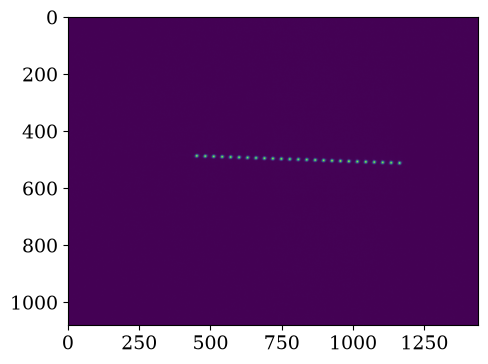

In [235]:
plt.imshow(image_float)

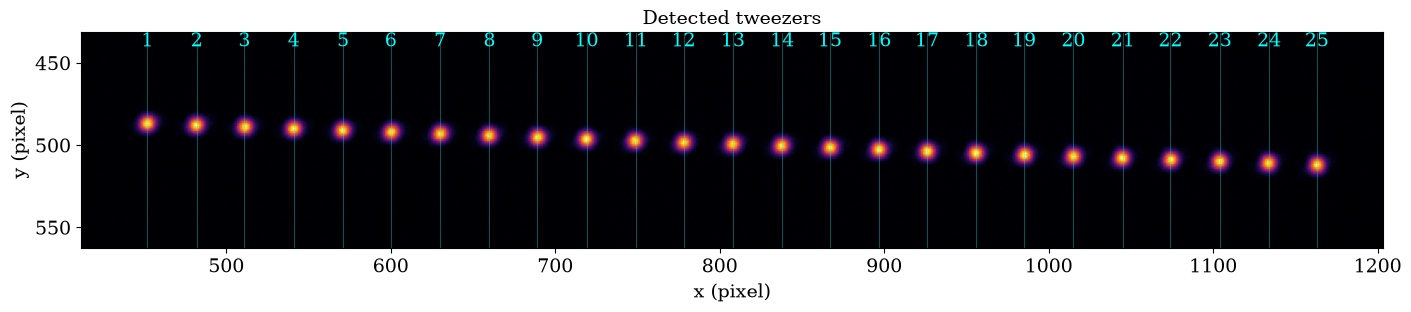

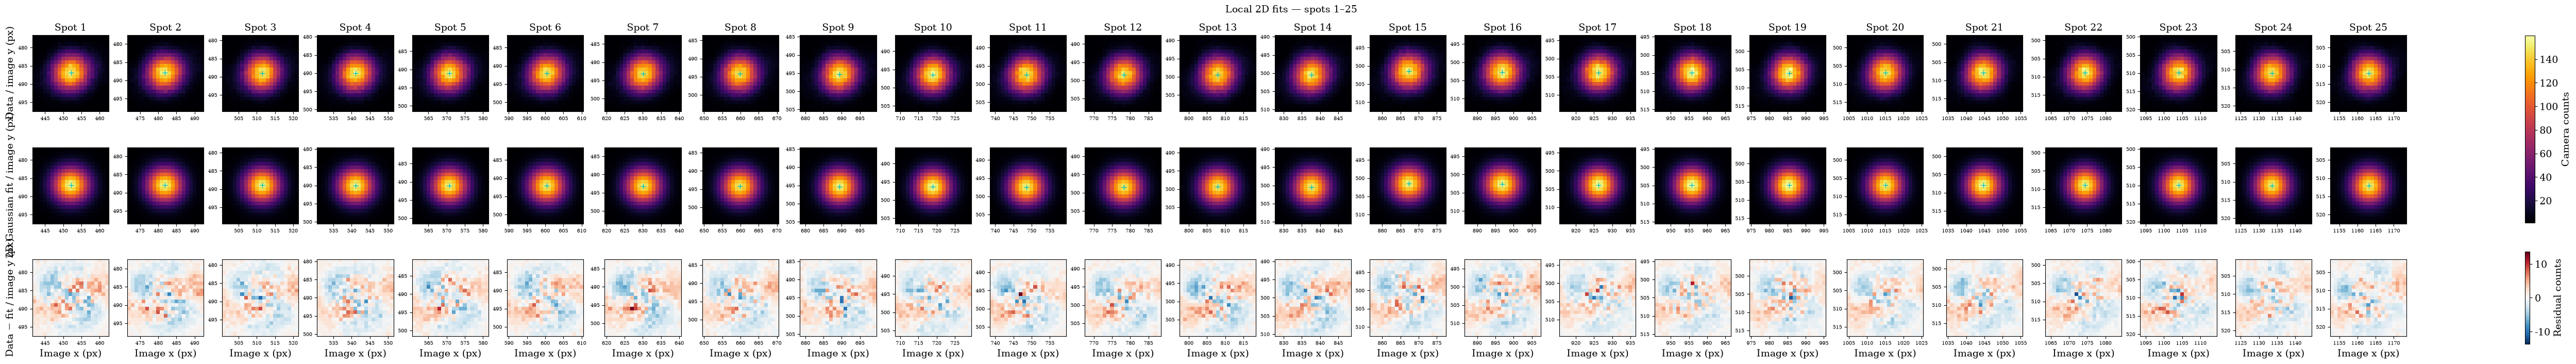

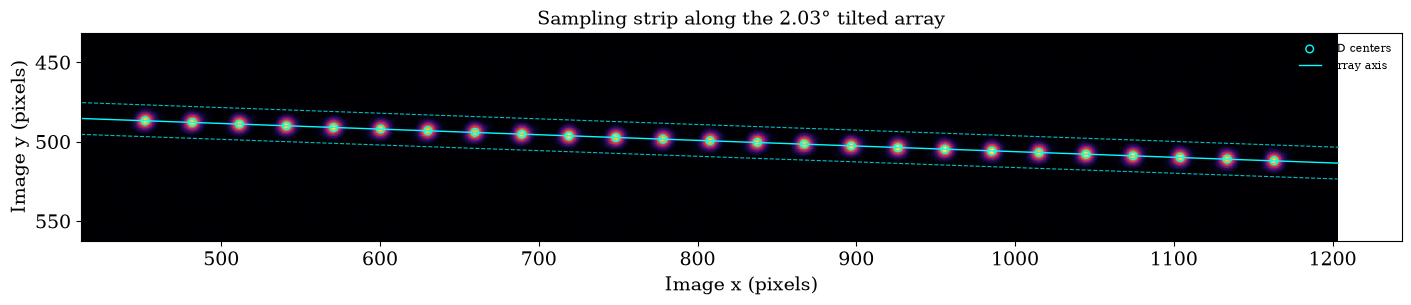

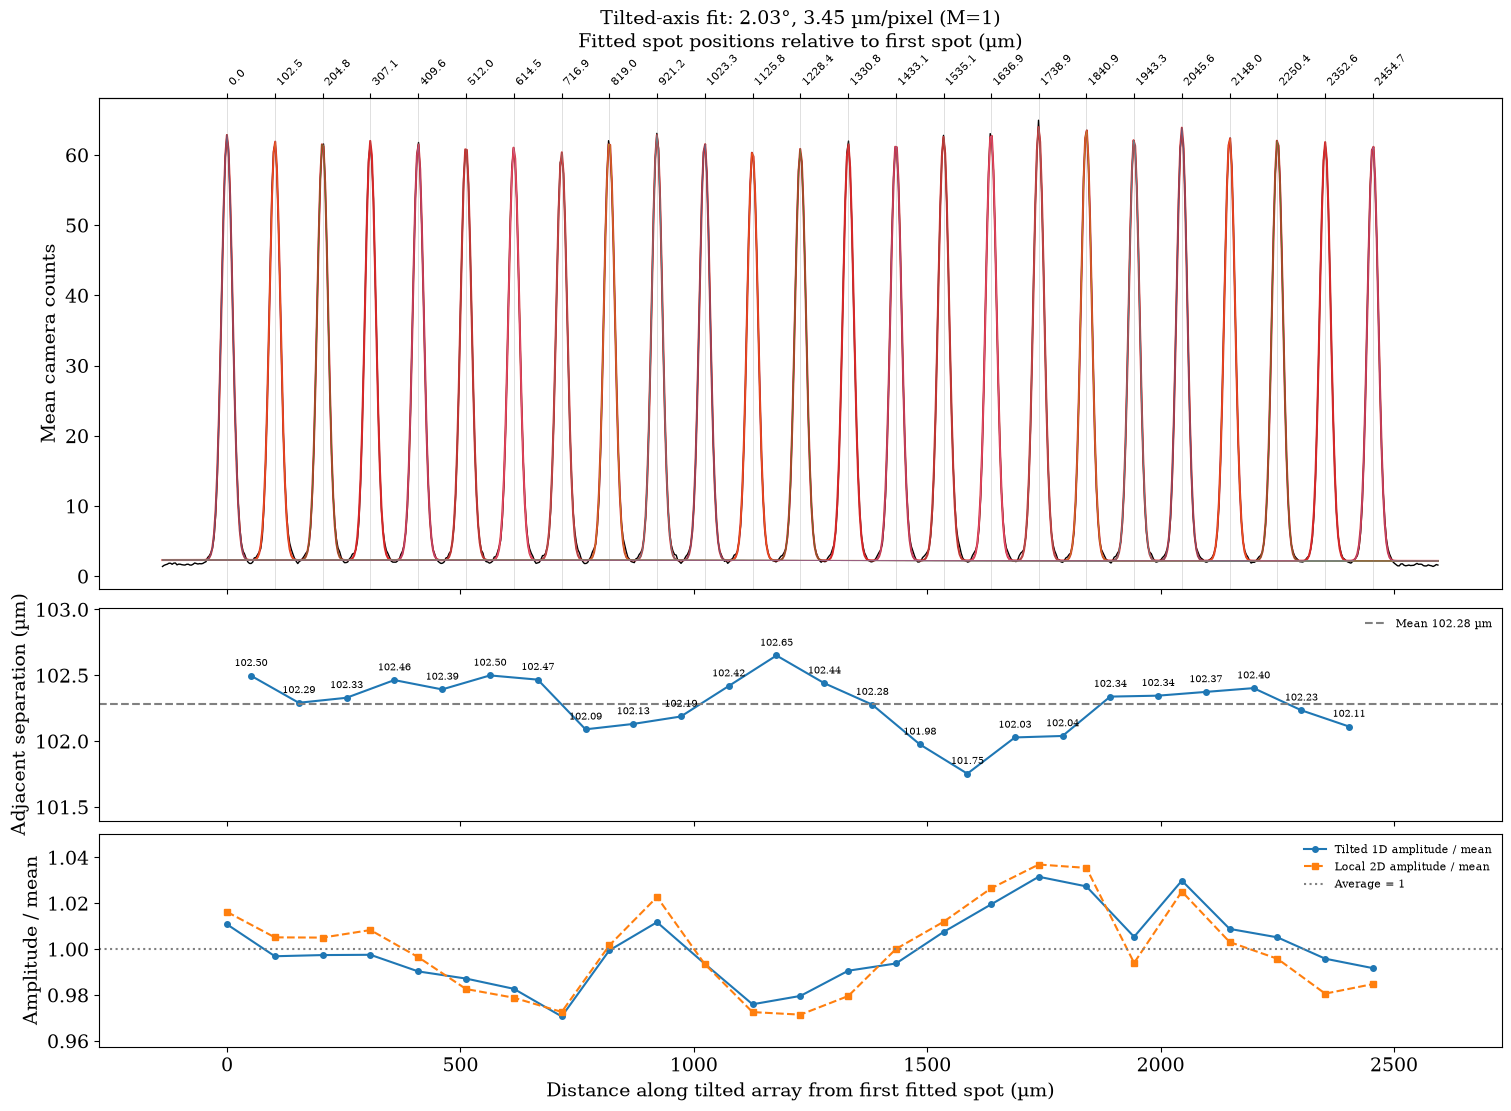

{'spots':     spot  distance_from_first_um  xp_center_px  amplitude_mean_counts  \
 0      1                0.000000   -355.913003              60.538693   
 1      2              102.496253   -326.203944              59.706689   
 2      3              204.787000   -296.554453              59.737397   
 3      4              307.115666   -266.893970              59.744603   
 4      5              409.578762   -237.194522              59.310567   
 5      6              511.970968   -207.515621              59.123956   
 6      7              614.469447   -177.805917              58.856141   
 7      8              716.935904   -148.105495              58.134970   
 8      9              819.024994   -118.514454              59.860595   
 9     10              921.155056    -88.911538              60.595417   
 10    11             1023.341638    -59.292239              59.510860   
 11    12             1125.759098    -29.606018              58.452515   
 12    13             1228.40

In [237]:
results = analyze_1D_tweezer_array(image_float,n_spots=N_spots,magnification=1, fit_config= {"min_peak_distance":20},plot=True, output_dir="./camera_data/calibration_without_objective")
# results = analyze_1D_tweezer_array(image_float,n_spots=N_spots,magnification=1, fit_config= {"min_peak_distance":20},plot=True)
results

## AOD RF-laser power response

In [221]:
def outter_function(f):
    # Verified 2026-11-04: relative VOLTAGE amplitudes, with a 60 mV base.
    # Frequencies are ascending; do not reverse or take a square root here.
    # Preserve the saved phase pattern to reproduce the verified uniformity.
    f = np.asarray(f, dtype=float)
    RF_f = np.linspace(95, 105, 25)
    RF_a = np.array([0.66800729, 0.67296096, 0.65927953, 0.67464961, 0.69453738,
       0.7072659 , 0.71753826, 0.69159211, 0.67017918, 0.64771386,
       0.63196057, 0.63125844, 0.64222887, 0.65596235, 0.65595104,
       0.63776837, 0.61643307, 0.61895003, 0.63652961, 0.64662543,
       0.6451588 , 0.61081098, 0.59993768, 0.61200622, 0.63861242])
    return np.interp(f, RF_f, RF_a)


In [222]:
N_spots = 25
CH0_INITIAL_FREQUENCIES_MHZ = SG.equally_spaced_frequencies_mhz(95, 105, N_spots)
# CH0_INITIAL_FREQUENCIES_MHZ = SG.generate_exact_frequencies_mhz([95])

In [230]:
CH0_INITIAL_PHASES = SG.generate_initial_phases(CH0_INITIAL_FREQUENCIES_MHZ)
initial_samples_matrix, output_ranges, initial_frequencies_next_mhz, initial_phases_next = SG.generate_static_signal({0: CH0_INITIAL_FREQUENCIES_MHZ}, {0:CH0_INITIAL_PHASES})

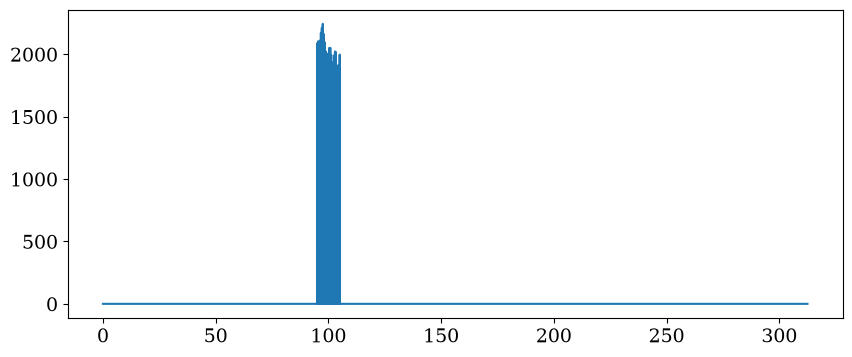

In [231]:
initial_samples_matrix[0]
spectrum = np.fft.rfft(initial_samples_matrix[0])
frequencies = np.fft.rfftfreq(len(initial_samples_matrix[0]), 1/625)
plt.plot(frequencies,np.abs(spectrum)/len(initial_samples_matrix[0]))

In [232]:
s = time.time()
AWG.setup_initial_sequence(initial_samples_matrix, output_ranges)
e = time.time()
e-s

0.0008549690246582031

In [233]:
AWG.start_initial_hold()

In [165]:
RF_relative_amplitude_list = np.linspace(0.5,0.8,51)
laser_power_list = []
AWG.stop()
AWG.clear()
for relative_amp in RF_relative_amplitude_list:
    def outter_function(f):
        f = np.asarray(f,dtype = float)
        RF_f = np.array([95,105])
        RF_p = np.array([relative_amp,relative_amp])
        return np.interp(f,RF_f, RF_p)
    CH0_INITIAL_RELATIVE_AMPLITUDES_C = np.ones(len(CH0_INITIAL_FREQUENCIES_MHZ))
    CH0_INITIAL_PHASES_C = SG.generate_initial_phases(CH0_INITIAL_FREQUENCIES_MHZ)
    initial_samples_matrix, output_ranges, initial_frequencies_next_mhz, initial_phases_next = SG.generate_static_signal({0: CH0_INITIAL_FREQUENCIES_MHZ}, {0:CH0_INITIAL_PHASES_C})
    AWG.setup_initial_sequence(initial_samples_matrix, output_ranges)
    AWG.start_initial_hold()
    frame = camera.capture(exposure_us=150, timeout_s=3)
    image_float = frame.image.astype('float64')
    results = analyze_1D_tweezer_array(image_float,n_spots=N_spots,fit_config= {"min_peak_distance":20},plot=False)
    laser_power_list.append(results["fitted_intensity"])
    AWG.stop()
    AWG.clear()

Text(0, 0.5, 'fitted intensity (a.u.)')

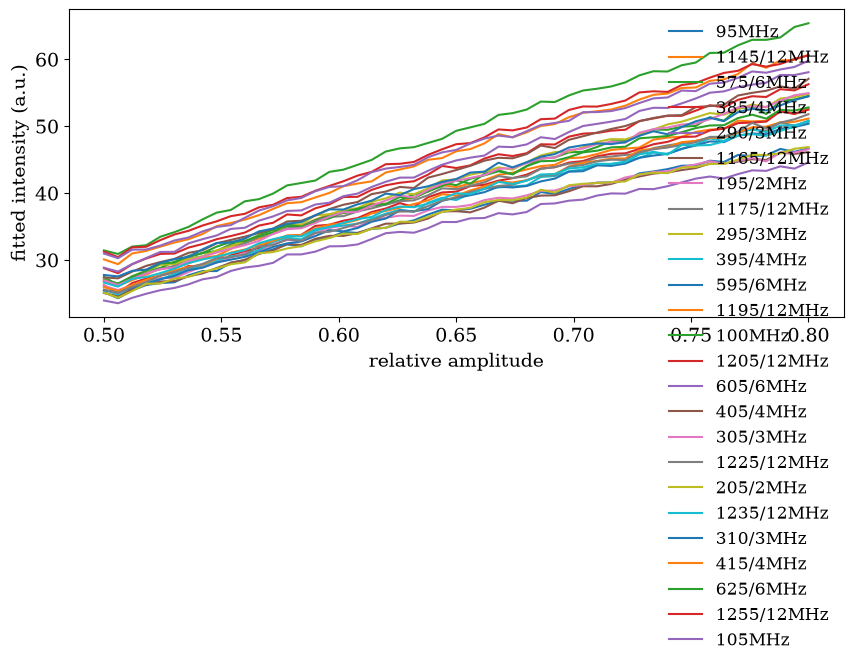

In [166]:
laser_power_list = np.array(laser_power_list)
for id_RF, RF_freq in enumerate(CH0_INITIAL_FREQUENCIES_MHZ):
    plt.plot(RF_relative_amplitude_list,laser_power_list[:,id_RF], label = f"{CH0_INITIAL_FREQUENCIES_MHZ[id_RF]}MHz")
plt.legend()
plt.xlabel("relative amplitude")
plt.ylabel("fitted intensity (a.u.)")

Calibrated relative amplitudes: [0.68526956 0.63628086 0.63474287 0.64325585 0.72271925 0.69529067
 0.68311769 0.63987994 0.62552139 0.65662339 0.66018685 0.65298345
 0.63646336 0.61123167 0.60845869 0.61640549 0.63553499 0.65468045
 0.68340918 0.65729    0.62801906 0.5957972  0.57237673 0.58770349
 0.58836041]


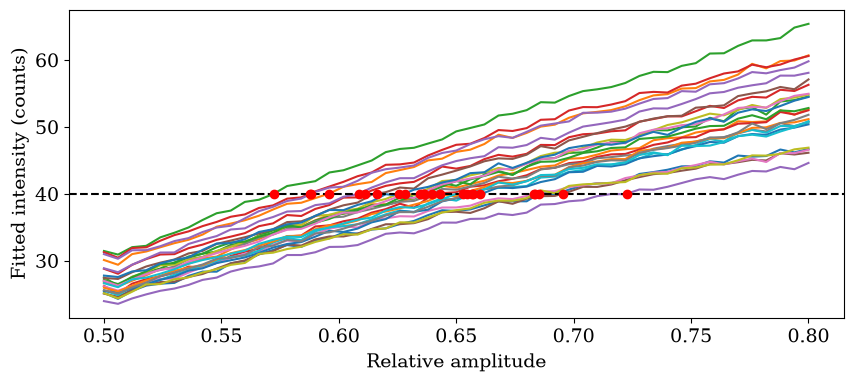

In [167]:
target_intensity = 40.0  # Choose an intensity reached by every curve.

x = np.asarray(RF_relative_amplitude_list, dtype=float)
intensities = np.asarray(laser_power_list, dtype=float)

calibrated_amplitudes = []
for spot, y in enumerate(intensities.T):
    # First upward crossing, avoiding the declining branch.
    crossings = np.flatnonzero(
        (y[:-1] <= target_intensity) & (y[1:] > target_intensity)
    )
    if len(crossings) == 0:
        raise ValueError(f"Spot {spot}: target intensity is not bracketed.")
    i = crossings[0]
    calibrated_amplitudes.append(
        np.interp(target_intensity, y[i:i+2], x[i:i+2])
    )

# Relative voltage amplitudes, in camera-spot order; no square root needed.
calibrated_amplitudes = np.array(calibrated_amplitudes)
print("Calibrated relative amplitudes:", calibrated_amplitudes)

plt.figure()
plt.plot(x, intensities)
plt.axhline(target_intensity, color="black", ls="--")
plt.scatter(
    calibrated_amplitudes,
    np.full(len(calibrated_amplitudes), target_intensity),
    color="red", zorder=5,
)
plt.xlabel("Relative amplitude")
plt.ylabel("Fitted intensity (counts)")
plt.show()


In [131]:
calibrated_amplitudes

array([0.69612127, 0.6385455 , 0.62610285, 0.64078897, 0.72093761,
       0.6922364 , 0.68697364, 0.63411677, 0.60964264, 0.6473071 ,
       0.66032849, 0.65475375, 0.64508274, 0.60428135, 0.59944237,
       0.60355273, 0.61506181, 0.64667079, 0.68847107, 0.65574284,
       0.6352389 , 0.59313   , 0.56486557, 0.57806688, 0.57401407])

# Feedback calibration — runnable experiment

Run the **first three cells** (imports and AWG classes), then the three code cells below. **Do not run the intervening sweep/demo/close cells.** No temporary agent scripts or `AGENT_*` variables are needed.

The execution cell opens the camera/AWG only if needed, stops live preview, applies the initial amplitudes, measures the initial distribution, optimizes, and takes **10 independent final verification images**. It saves raw images, per-tone results, exact waveform/settings, a comparison plot, and `REPORT.md` in a new directory.

The default initial amplitudes are **0.65 for all tones**, the safe starting point used in the successful optimization—not the older inherited amplitude-1 waveform above the current RF-power limit. The report compares this explicitly applied initial setting with the verified final setting.

**Mapping verified by end-tone probes:** raw camera leftmost = 105 MHz, rightmost = 95 MHz. Recheck this if the optical/image orientation changes. The original phases are retained throughout the run. Updates use `ratio**(-0.3)` capped at ±5%; no exact global I–A or I–A² model is assumed.

This stops/reloads the AWG between updates; it is not uninterrupted trapping. On success, RF remains running by default, the monitor stays stopped, and the camera remains open but disarmed. On failure, playback stops and a failure record is saved. Existing HOLDLAST stop mode does not guarantee zero volts.


In [217]:
from datetime import datetime, timezone
from pathlib import Path
import json
import pandas as pd
from Equipments.ThorCamLinux import Camera, save_frame
from DataProcessing.TweezerAnalyze import analyze_1D_tweezer_array

plt.rcParams['font.family'] = 'DejaVu Serif'

RUN_FEEDBACK = True  # Change to True after reviewing these settings.
FEEDBACK_CFG = AWGConfig()
FEEDBACK_CHANNEL = AWGChannelConfig(
    index=0, single_tone_amplitude_mv=50, load_ohm=50,
    max_average_output_power_dbm=-2,
)
CAMERA_SERIAL = None  # Reuse the open camera, or auto-select a single connected camera.
N_TONES = 25
TONE_TO_SPOT = np.arange(N_TONES)[::-1]  # Measured raw-image mapping.
print(TONE_TO_SPOT)
START_AMPLITUDES = np.full(N_TONES, 0.65)  # RF-frequency order, 95 -> 105 MHz.
print(START_AMPLITUDES)
AMPLITUDE_LIMITS = (0.5, 1)  # Measured calibration range.
EXPOSURE_US = 150
CAMERA_GAIN = 0
GAIN = 0.3
MAX_STEP = 0.05
MAX_UPDATES = 10
TARGET_MAX_ERROR = 0.01  # Every mean spot intensity within 1% of the array mean.
FRAMES_PER_STEP = 3
FINAL_FRAMES = 10
LEAVE_RF_RUNNING = True
SAVE_ROOT = Path('camera_data')
FIT_CONFIG = {'min_peak_distance': 20}


[24 23 22 21 20 19 18 17 16 15 14 13 12 11 10  9  8  7  6  5  4  3  2  1
  0]
[0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65
 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65 0.65]


In [218]:
def apply_feedback_amplitudes(awg, generator, frequencies, phases, amplitudes):
    """Check the proposed waveform before stopping/reloading the card."""
    a = np.asarray(amplitudes, dtype=float).copy()
    if a.shape != (N_TONES,) or not np.isfinite(a).all() or np.any(a < AMPLITUDE_LIMITS[0]) or np.any(a > AMPLITUDE_LIMITS[1]):
        raise ValueError('Amplitude outside the measured calibration range.')
    generator.get_calibrated_relative_amplitude = lambda f, a=a: np.interp(
        np.asarray(f, dtype=float), np.asarray(frequencies, dtype=float), a)
    samples, ranges, _, _ = generator.generate_static_signal({0: frequencies}, {0: phases})
    power_dbm = float(awg.compute_awg_output_power(samples[0], ranges[0]))
    peak = np.max(np.abs(samples.astype(float))) / awg.config.dac_max_code
    if not np.isfinite(power_dbm) or power_dbm > FEEDBACK_CHANNEL.max_average_output_power_dbm or peak > awg.config.dac_headroom + 2 / awg.config.dac_max_code:
        raise ValueError('Waveform exceeds RF-power or DAC-headroom limits.')
    awg.clear()
    awg.setup_initial_sequence(samples, ranges)
    actual_range = float(awg.channels[0].amp())
    actual_power = float(awg.compute_awg_output_power(samples[0], actual_range))
    if abs(actual_range - ranges[0]) > 1 or not np.isfinite(actual_power) or actual_power > FEEDBACK_CHANNEL.max_average_output_power_dbm:
        raise ValueError('Hardware output range or RF power failed verification.')
    awg.start_initial_hold()
    time.sleep(0.35)
    return samples, {0: actual_range}, actual_power


def measure_feedback_image_set(camera, folder, label, count, reference_centers=None):
    """Save and fit fresh frames; return per-frame intensities in camera order."""
    intensities, fit_r2 = [], []
    for frame_index in range(count):
        shot = camera.capture(exposure_us=EXPOSURE_US, timeout_s=3)
        save_frame(shot, folder / f'{label}_{frame_index:02d}.tif')
        if np.any(shot.image >= (1 << shot.bit_depth) - 1):
            raise RuntimeError('Camera saturation: reduce exposure and restart the run.')
        fit = analyze_1D_tweezer_array(
            shot.image, n_spots=N_TONES, magnification=1,
            fit_config=FIT_CONFIG, plot=False,
        )
        if fit['quality_issues'] or not np.isfinite(fit['r_squared']) or fit['r_squared'] < 0.98:
            raise RuntimeError('Unreliable image fit: inspect the saved frame before continuing.')
        values = np.asarray(fit['fitted_intensity'], dtype=float)
        if values.shape != (N_TONES,) or not np.isfinite(values).all() or np.any(values <= 0):
            raise RuntimeError('Invalid fitted intensities.')
        centers = fit['spots'][['core_x_center_px', 'core_y_center_px']].to_numpy()
        if reference_centers is None:
            reference_centers = centers.copy()
        shift = centers - reference_centers
        shift -= np.median(shift, axis=0)  # Allow a rigid translation, not a spot swap.
        if np.max(np.linalg.norm(shift, axis=1)) > 5:
            raise RuntimeError('Relative spot positions changed; inspect the tone mapping.')
        intensities.append(values)
        fit_r2.append(fit['r_squared'])
    intensities = np.asarray(intensities)
    mean = intensities.mean(axis=0)
    ratios = mean / mean.mean()
    record = dict(
        label=label, intensities=intensities, mean_intensity=mean,
        mean_counts=float(mean.mean()), cv=float(np.std(ratios)),
        max_error=float(np.max(np.abs(ratios - 1))),
        r_squared=np.asarray(fit_r2), reference_centers=reference_centers,
    )
    with (folder / f'{label}_measurement.npz').open('xb') as file:
        np.savez(file, **record)
    print(f'{label}: mean {record["mean_counts"]:.3f} counts, '
          f'RMS {record["cv"]:.2%}, max deviation {record["max_error"]:.2%}')
    return record


iteration_00: mean 60.377 counts, RMS 8.09%, max deviation 16.80%
iteration_01: mean 60.430 counts, RMS 3.79%, max deviation 8.85%
iteration_02: mean 60.136 counts, RMS 2.09%, max deviation 4.49%
iteration_03: mean 59.576 counts, RMS 0.89%, max deviation 1.77%
iteration_04: mean 59.509 counts, RMS 0.60%, max deviation 1.17%
iteration_05: mean 60.078 counts, RMS 0.32%, max deviation 0.65%
final_verification: mean 59.836 counts, RMS 0.42%, max deviation 0.71%


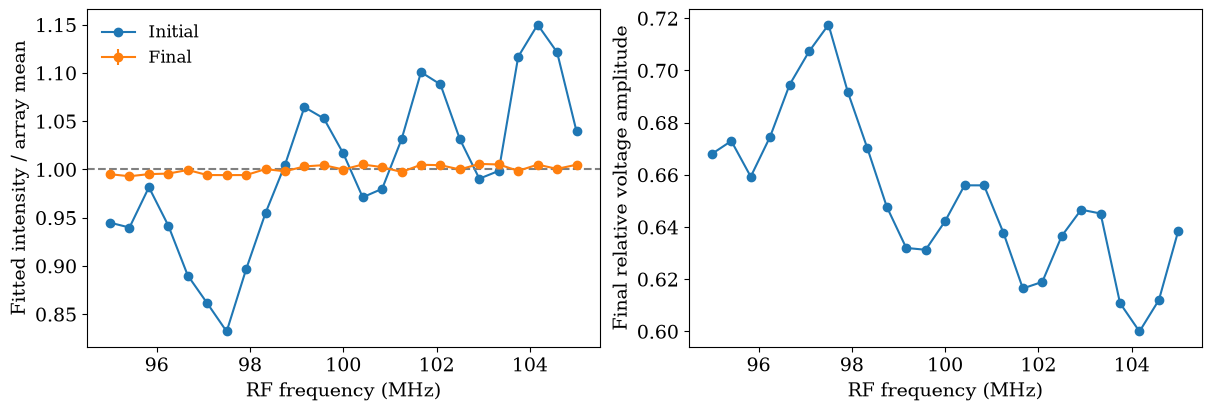

Verified target reached: True
Final amplitudes (ascending RF frequency): [0.66800729 0.67296096 0.65927953 0.67464961 0.69453738 0.7072659
 0.71753826 0.69159211 0.67017918 0.64771386 0.63196057 0.63125844
 0.64222887 0.65596235 0.65595104 0.63776837 0.61643307 0.61895003
 0.63652961 0.64662543 0.6451588  0.61081098 0.59993768 0.61200622
 0.63861242]
Report: /home/fengxy/ExperimentCode/camera_data/feedback_20261104T162238_358157Z/REPORT.md


,frequency_mhz,camera_spot_1based,initial_relative_amplitude,final_relative_amplitude,initial_intensity_counts,final_intensity_counts,initial_intensity_ratio,final_intensity_ratio,final_intensity_sem_counts,final_ratio_sem
0,95.000000,25,0.65,0.668007,57.044900,59.538013,0.944811,0.995020,0.234515,0.002167
1,95.416667,24,0.65,0.672961,56.740737,59.412476,0.939773,0.992922,0.268339,0.001395
2,95.833333,23,0.65,0.659280,59.260936,59.543166,0.981514,0.995106,0.191862,0.001361
3,96.250000,22,0.65,0.674650,56.857217,59.577034,0.941702,0.995672,0.186345,0.001398
4,96.666667,21,0.65,0.694537,53.737923,59.801854,0.890039,0.999429,0.198128,0.001665
5,97.083333,20,0.65,0.707266,52.003122,59.487407,0.861306,0.994174,0.254548,0.002003
6,97.500000,19,0.65,0.717538,50.235365,59.483015,0.832027,0.994101,0.183664,0.001660
7,97.916667,18,0.65,0.691592,54.123924,59.486579,0.896432,0.994160,0.228388,0.001302
8,98.333333,17,0.65,0.670179,57.649031,59.854931,0.954817,1.000316,0.285986,0.001668
9,98.750000,16,0.65,0.647714,60.660948,59.718542,1.004702,0.998037,0.222650,0.001397


In [219]:
if not RUN_FEEDBACK:
    print('Hardware disabled. Set RUN_FEEDBACK = True in the settings cell when ready.')
else:
    # Validate settings before touching hardware.
    mapping = np.asarray(TONE_TO_SPOT)
    if mapping.shape != (N_TONES,) or mapping.dtype.kind not in 'iu' or not np.array_equal(np.sort(mapping), np.arange(N_TONES)):
        raise ValueError('TONE_TO_SPOT must be a verified permutation of camera spot indices.')
    if not isinstance(MAX_UPDATES, int) or MAX_UPDATES < 0 or not 0 < GAIN <= 1 or not 0 < MAX_STEP <= 0.05:
        raise ValueError('Use MAX_UPDATES >= 0, 0 < GAIN <= 1, and 0 < MAX_STEP <= 0.05.')
    if not 0 < TARGET_MAX_ERROR < 1 or any(not isinstance(n, int) or n < 2 for n in (FRAMES_PER_STEP, FINAL_FRAMES)):
        raise ValueError('Use a positive tolerance below 1 and at least two frames per measurement.')
    run_directory = SAVE_ROOT / ('feedback_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
    run_directory.mkdir(parents=True, exist_ok=False)  # Never overwrite a previous run.
    feedback_history = []
    active_awg = None
    try:
        if globals().get('monitor') is not None:
            monitor.stop()
        if globals().get('AWG') is None or AWG.card is None:
            AWG = AWG_sequence_mode(FEEDBACK_CFG, [FEEDBACK_CHANNEL])
            active_awg = AWG
            AWG.open()
        active_awg = AWG
        if vars(AWG.config) != vars(FEEDBACK_CFG) or len(AWG.channel_configs) != 1 or vars(AWG.channel_configs[0]) != vars(FEEDBACK_CHANNEL):
            raise ValueError('Open AWG configuration differs: close it explicitly, then rerun with matching settings.')
        if globals().get('camera') is None or camera._camera is None:
            camera = Camera(CAMERA_SERIAL)
        elif CAMERA_SERIAL is not None and camera.serial != CAMERA_SERIAL:
            raise ValueError('The open camera serial does not match CAMERA_SERIAL.')
        camera.configure(exposure_us=EXPOSURE_US, gain=CAMERA_GAIN)

        SG = signal_generator(FEEDBACK_CFG, [FEEDBACK_CHANNEL])
        frequencies = SG.equally_spaced_frequencies_mhz(95, 105, N_TONES)
        SG.get_calibrated_relative_amplitude = lambda f: np.ones_like(f, dtype=float)
        phases = SG.generate_initial_phases(frequencies)  # Original equal-weight phase pattern.
        amplitudes = np.asarray(START_AMPLITUDES, dtype=float).copy()
        reference_centers = None
        best = None
        for turn in range(MAX_UPDATES + 1):
            samples, ranges, power_dbm = apply_feedback_amplitudes(AWG, SG, frequencies, phases, amplitudes)
            record = measure_feedback_image_set(camera, run_directory, f'iteration_{turn:02d}', FRAMES_PER_STEP, reference_centers)
            record.update(amplitudes=amplitudes.copy(), power_dbm=power_dbm, output_range_mv=ranges[0])
            feedback_history.append(record)
            reference_centers = record['reference_centers']
            if best is None or record['max_error'] < best['max_error']:
                best = record
            if record['max_error'] <= TARGET_MAX_ERROR or turn == MAX_UPDATES:
                break
            if turn >= 2 and record['max_error'] > 1.4 * best['max_error'] and record['max_error'] > 0.025:
                print('Uniformity worsened; verify the best measured setting instead of continuing.')
                break
            intensity = record['mean_intensity'][mapping]
            factor = np.clip((intensity / intensity.mean()) ** (-GAIN), 1 - MAX_STEP, 1 + MAX_STEP)
            amplitudes = amplitudes * factor

        # Verify the best setting with independent images, not the images used to select it.
        if not np.array_equal(amplitudes, best['amplitudes']):
            amplitudes = best['amplitudes'].copy()
            samples, ranges, power_dbm = apply_feedback_amplitudes(AWG, SG, frequencies, phases, amplitudes)
        time.sleep(2)
        final = measure_feedback_image_set(camera, run_directory, 'final_verification', FINAL_FRAMES, reference_centers)
        initial = feedback_history[0]
        final.update(amplitudes=amplitudes.copy(), power_dbm=power_dbm, output_range_mv=ranges[0])
        converged = final['max_error'] <= TARGET_MAX_ERROR
        relative_frames = final['intensities'] / final['intensities'].mean(axis=1, keepdims=True)
        ratio_sem = relative_frames.std(axis=0, ddof=1) / np.sqrt(FINAL_FRAMES)
        intensity_sem = final['intensities'].std(axis=0, ddof=1) / np.sqrt(FINAL_FRAMES)
        comparison = pd.DataFrame({
            'frequency_mhz': np.asarray(frequencies, dtype=float), 'camera_spot_1based': mapping + 1,
            'initial_relative_amplitude': initial['amplitudes'], 'final_relative_amplitude': amplitudes,
            'initial_intensity_counts': initial['mean_intensity'][mapping],
            'final_intensity_counts': final['mean_intensity'][mapping],
            'initial_intensity_ratio': (initial['mean_intensity'] / initial['mean_counts'])[mapping],
            'final_intensity_ratio': (final['mean_intensity'] / final['mean_counts'])[mapping],
            'final_intensity_sem_counts': intensity_sem[mapping], 'final_ratio_sem': ratio_sem[mapping],
        })
        comparison.to_csv(run_directory / 'initial_final_per_tone.csv', index=False)
        pd.DataFrame([{key: r[key] for key in ('label', 'mean_counts', 'cv', 'max_error', 'power_dbm')} for r in feedback_history + [final]]).to_csv(run_directory / 'measurement_history.csv', index=False)
        # Save every applied amplitude vector, so intermediate measurements are reproducible.
        np.savez(run_directory / 'amplitude_history.npz', amplitudes=np.array([r['amplitudes'] for r in feedback_history]),
                 frequencies_mhz=np.asarray(frequencies, dtype=float), phases_rad=phases, tone_to_spot=mapping)
        np.savez(run_directory / 'final_waveform.npz', samples=samples, output_range_mv=ranges[0],
                 relative_amplitudes=amplitudes, phases_rad=phases, tone_to_spot=mapping,
                 frequencies_mhz=np.asarray(frequencies, dtype=float))
        settings = dict(
            frequencies_mhz=np.asarray(frequencies, dtype=float).tolist(), exact_frequencies_mhz=[str(f) for f in frequencies],
            relative_amplitudes_in_frequency_order=amplitudes.tolist(), phases_rad=phases.tolist(),
            tone_to_spot=mapping.tolist(), base_tone_amplitude_mv=FEEDBACK_CHANNEL.single_tone_amplitude_mv,
            sample_rate_mhz=FEEDBACK_CFG.sample_rate_mhz, output_range_mv=ranges[0],
            average_rf_power_dbm=power_dbm, rf_power_limit_dbm=FEEDBACK_CHANNEL.max_average_output_power_dbm,
            exposure_us=EXPOSURE_US, camera_gain_index=CAMERA_GAIN, camera_serial=camera.serial,
            control_gain=GAIN, max_fractional_step=MAX_STEP, amplitude_limits=list(AMPLITUDE_LIMITS),
            initial_frame_count=FRAMES_PER_STEP, verification_frame_count=FINAL_FRAMES,
            initial_cv=initial['cv'], initial_max_error=initial['max_error'],
            intensity_cv=final['cv'], max_relative_deviation=final['max_error'],
            mean_intensity_camera_counts=final['mean_counts'], target_max_error=TARGET_MAX_ERROR,
            converged=bool(converged), rf_output_running=bool(LEAVE_RF_RUNNING),
        )
        (run_directory / 'final_settings.json').write_text(json.dumps(settings, indent=2))
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
        axes[0].plot(comparison.frequency_mhz, comparison.initial_intensity_ratio, 'o-', label='Initial')
        axes[0].errorbar(comparison.frequency_mhz, comparison.final_intensity_ratio, yerr=comparison.final_ratio_sem, fmt='o-', label='Final')
        axes[0].axhline(1, color='gray', ls='--')
        axes[0].set(xlabel='RF frequency (MHz)', ylabel='Fitted intensity / array mean')
        axes[0].legend()
        axes[1].plot(comparison.frequency_mhz, amplitudes, 'o-')
        axes[1].set(xlabel='RF frequency (MHz)', ylabel='Final relative voltage amplitude')
        fig.savefig(run_directory / 'uniformity_report.png', dpi=180)
        plt.show()
        report = f"""# AOD feedback report

Camera {camera.serial}; exposure {EXPOSURE_US} µs; gain index {CAMERA_GAIN}.
Mapping: RF tone j maps to zero-based camera spot TONE_TO_SPOT[j], saved in final_settings.json.
Intensities are fitted peak amplitudes of the transversely averaged strip, not integrated optical powers.

| Metric | Initial ({FRAMES_PER_STEP} frames) | Verified final ({FINAL_FRAMES} frames) |
|---|---:|---:|
| Mean fitted intensity (counts) | {initial['mean_counts']:.4f} | {final['mean_counts']:.4f} |
| RMS nonuniformity | {initial['cv']:.3%} | {final['cv']:.3%} |
| Maximum deviation from mean | {initial['max_error']:.3%} | {final['max_error']:.3%} |
| Predicted RF power (dBm) | {initial['power_dbm']:.3f} | {power_dbm:.3f} |

Verified target ({TARGET_MAX_ERROR:.2%} maximum deviation) reached: **{converged}**.
A completed run does not imply convergence. Uniformity can drift after verification.
Final spot means span {final['mean_intensity'].min():.4f}–{final['mean_intensity'].max():.4f} counts.
RF power is calculated from DAC samples and the output range into 50 ohms, not measured with a power meter.

![Comparison](uniformity_report.png)

Full per-tone values: initial_final_per_tone.csv. Settings/phases: final_settings.json.
Exact final samples: final_waveform.npz. Raw images and metadata are stored alongside this report.
RF left running at completion: {LEAVE_RF_RUNNING}. Live monitor stopped; camera open/disarmed.
AWG.stop() uses the existing HOLDLAST mode and is not a guaranteed zero-voltage interlock.
"""
        (run_directory / 'REPORT.md').write_text(report)
        # Retain the applied calibration for subsequent waveform generation.
        feedback_amplitudes = amplitudes.copy()
        CH0_INITIAL_FREQUENCIES_MHZ = frequencies.copy()
        CH0_INITIAL_RELATIVE_AMPLITUDES = amplitudes.copy()
        CH0_INITIAL_PHASES = phases.copy()
        initial_samples_matrix, output_ranges = samples.copy(), ranges.copy()
        outter_function = SG.get_calibrated_relative_amplitude
        optimized_intensity = final['mean_intensity'].copy()
        feedback_experiment = dict(initial=initial, final=final, history=feedback_history,
                                   settings=settings, directory=run_directory, converged=bool(converged))
        if not LEAVE_RF_RUNNING:
            AWG.stop()
        print('Verified target reached:', converged)
        print('Final amplitudes (ascending RF frequency):', feedback_amplitudes)
        print('Report:', (run_directory / 'REPORT.md').resolve())
        display(comparison)
    except BaseException as exc:
        if active_awg is not None:
            active_awg.stop()
        (run_directory / 'FAILED.txt').write_text(f'{type(exc).__name__}: {exc}\nPlayback stopped; partial raw data retained.\n')
        raise


In [220]:
feedback_amplitudes

array([0.66800729, 0.67296096, 0.65927953, 0.67464961, 0.69453738,
       0.7072659 , 0.71753826, 0.69159211, 0.67017918, 0.64771386,
       0.63196057, 0.63125844, 0.64222887, 0.65596235, 0.65595104,
       0.63776837, 0.61643307, 0.61895003, 0.63652961, 0.64662543,
       0.6451588 , 0.61081098, 0.59993768, 0.61200622, 0.63861242])

## Verified hardware optimization — 2026-11-04 (UTC)

**Final 25-spot distribution: RMS nonuniformity 0.423%, maximum deviation 0.788%**, verified using 10 fresh images at 150 µs exposure and gain index 0. Original equal-amplitude distribution: RMS 10.571%, maximum deviation 22.869% (3 images).

Mean fitted intensity changed from **107.202 to 77.094 camera counts**; the final setting uses less RF power to stay below the current −2 dBm limit. Final per-spot means span **76.487–77.661 counts**. This is peak-intensity uniformity, not calibrated optical-power uniformity.

**Important mapping correction:** independent 4% end-tone probes showed **raw camera leftmost = 105 MHz; rightmost = 95 MHz**. Use `TONE_TO_SPOT = np.arange(25)[::-1]`. The opposite mapping made feedback worse and was rejected.

The final waveform was left running at completion; the live monitor was stopped. `SG`, `outter_function`, `feedback_amplitudes`, and `CH0_INITIAL_RELATIVE_AMPLITUDES` in the live kernel retain the optimized calibration. `AWG.stop()` stops playback (existing HOLDLAST mode is not a guaranteed zero-voltage interlock).

[Full report](camera_data/uniformity_optimization_20261104T154316Z/REPORT.md) · [Per-tone CSV](camera_data/uniformity_optimization_20261104T154316Z/initial_final_per_tone.csv) · [Exact settings](camera_data/uniformity_optimization_20261104T154316Z/final_settings.json)

![Uniformity result](camera_data/uniformity_optimization_20261104T154316Z/uniformity_report.png)


In [185]:
# Load the saved result without touching hardware.
import pandas as pd
optimized_directory = Path("camera_data/uniformity_optimization_20261104T154316Z")
optimized_settings = json.loads((optimized_directory / "final_settings.json").read_text())
optimized_amplitudes = np.array(optimized_settings["relative_amplitudes_in_frequency_order"])
optimized_frequencies_mhz = np.array([Fraction(f) for f in optimized_settings["exact_frequencies_mhz"]], dtype=object)
optimized_phases = np.array(optimized_settings["phases_rad"])
display(pd.read_csv(optimized_directory / "initial_final_per_tone.csv"))


,frequency_mhz,camera_spot_1based,initial_relative_amplitude,final_relative_amplitude,final_peak_rf_amplitude_mv,initial_intensity_counts,final_intensity_counts,initial_intensity_ratio,final_intensity_ratio,final_intensity_sem_counts,final_ratio_sem
0,95.000000,25,1.000002,0.673812,40.428749,98.482949,76.486578,0.918667,0.992123,0.332405,0.001786
1,95.416667,24,1.000002,0.678067,40.684036,101.012268,76.799117,0.942261,0.996177,0.251110,0.000780
2,95.833333,23,1.000002,0.659921,39.595256,115.001216,77.204989,1.072752,1.001442,0.256701,0.001038
3,96.250000,22,0.999996,0.675667,40.540024,104.313900,77.019870,0.973059,0.999041,0.246752,0.001664
4,96.666667,21,1.000001,0.697511,41.850641,94.697807,76.816206,0.883358,0.996399,0.271332,0.000926
5,97.083333,20,1.000001,0.712894,42.773663,89.142334,76.885926,0.831536,0.997303,0.260578,0.001263
6,97.500000,19,1.000001,0.724132,43.447892,82.686419,76.843053,0.771314,0.996747,0.314685,0.001556
7,97.916667,18,0.999997,0.694040,41.642426,98.774609,76.667793,0.921387,0.994474,0.278655,0.001259
8,98.333333,17,0.999997,0.670384,40.223021,108.388121,76.702838,1.011064,0.994928,0.201802,0.000935
9,98.750000,16,1.000003,0.650781,39.046857,111.466514,76.820194,1.039780,0.996450,0.247261,0.001140
